In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv('employee_sla_status.csv')
df

,Employee_ID,Tasks_Assigned,Tasks_Completed,Avg_TAT_Hours,Error_Rate,Quality_Score,Escalations,Rework_Count,Experience_Years,Team,Shift,SLA_Status
0,EMP_6439,104,104,2.27,10.89,83.62,1,6,2.1,Support,Night,Met
1,EMP_8984,108,108,2.54,3.88,79.96,6,13,1.4,Ads,Day,Breached
2,EMP_8559,184,85,4.24,11.60,98.72,3,11,7.9,Ads,Night,Breached
3,EMP_559,119,119,NaN,NaN,NaN,8,12,4.0,Support,Day,Breached
4,EMP_8376,139,139,5.13,8.30,88.55,6,14,7.4,Support,Day,Breached
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,EMP_2467,120,120,3.50,8.78,64.52,9,0,0.9,QA,Night,Breached
9996,EMP_8837,192,105,5.03,8.91,76.35,8,7,2.8,Ads,Day,Breached
9997,EMP_2977,86,86,8.76,12.65,71.27,9,3,6.3,Moderation,Day,Breached
9998,EMP_6881,177,93,6.24,3.43,61.15,0,4,5.9,QA,Day,Breached


In [2]:
df.head()

,Employee_ID,Tasks_Assigned,Tasks_Completed,Avg_TAT_Hours,Error_Rate,Quality_Score,Escalations,Rework_Count,Experience_Years,Team,Shift,SLA_Status
0,EMP_6439,104,104,2.27,10.89,83.62,1,6,2.1,Support,Night,Met
1,EMP_8984,108,108,2.54,3.88,79.96,6,13,1.4,Ads,Day,Breached
2,EMP_8559,184,85,4.24,11.60,98.72,3,11,7.9,Ads,Night,Breached
3,EMP_559,119,119,NaN,NaN,NaN,8,12,4.0,Support,Day,Breached
4,EMP_8376,139,139,5.13,8.30,88.55,6,14,7.4,Support,Day,Breached


In [3]:
df.tail()

,Employee_ID,Tasks_Assigned,Tasks_Completed,Avg_TAT_Hours,Error_Rate,Quality_Score,Escalations,Rework_Count,Experience_Years,Team,Shift,SLA_Status
9995,EMP_2467,120,120,3.50,8.78,64.52,9,0,0.9,QA,Night,Breached
9996,EMP_8837,192,105,5.03,8.91,76.35,8,7,2.8,Ads,Day,Breached
9997,EMP_2977,86,86,8.76,12.65,71.27,9,3,6.3,Moderation,Day,Breached
9998,EMP_6881,177,93,6.24,3.43,61.15,0,4,5.9,QA,Day,Breached
9999,EMP_4452,124,124,5.16,5.97,94.01,3,11,4.5,Support,Day,Met


In [4]:
df.replace("", pd.NA, inplace=True)

In [5]:
df.dtypes

Employee_ID          object
Tasks_Assigned        int64
Tasks_Completed       int64
Avg_TAT_Hours       float64
Error_Rate          float64
Quality_Score       float64
Escalations           int64
Rework_Count          int64
Experience_Years    float64
Team                 object
Shift                object
SLA_Status           object
dtype: object

In [6]:
team=df['Team'].value_counts()
team

Team
Moderation    2592
Support       2540
QA            2454
Ads           2414
Name: count, dtype: int64

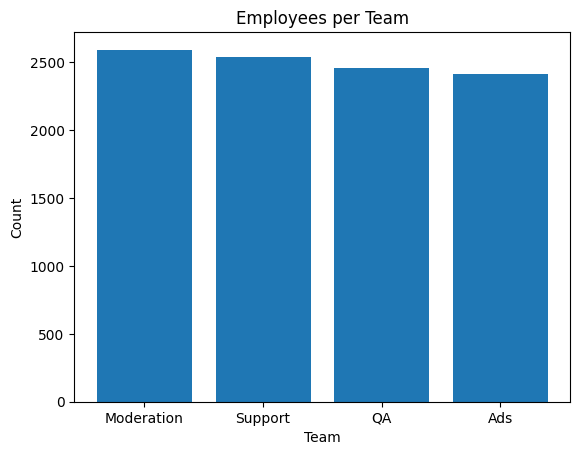

In [7]:
plt.bar(team.index,team.values)
plt.xlabel("Team")
plt.ylabel("Count")
plt.title("Employees per Team")
plt.show()


In [8]:
shift=df['Shift'].value_counts()
shift

Shift
Day      5057
Night    4943
Name: count, dtype: int64

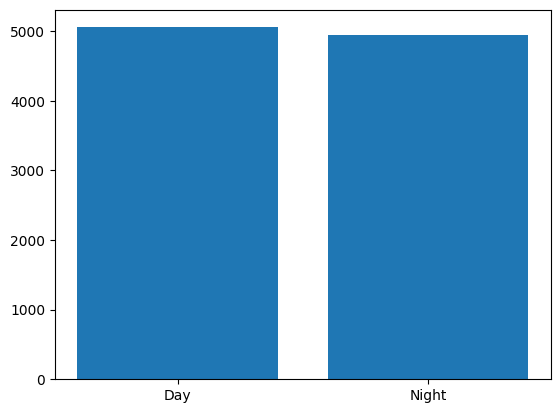

In [9]:
plt.bar(shift.index,shift.values)
plt.show()

In [10]:
sla=df['SLA_Status'].value_counts()
sla

SLA_Status
Breached    6000
Met         4000
Name: count, dtype: int64

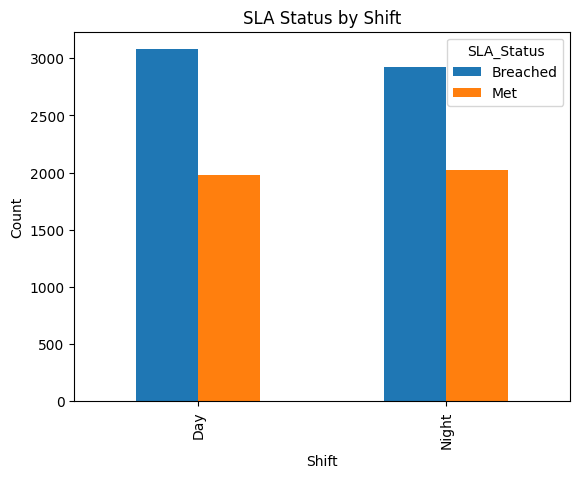

In [11]:
shift_sla = pd.crosstab(df['Shift'], df['SLA_Status'])

shift_sla.plot(kind='bar')
plt.title("SLA Status by Shift")
plt.ylabel("Count")
plt.show()

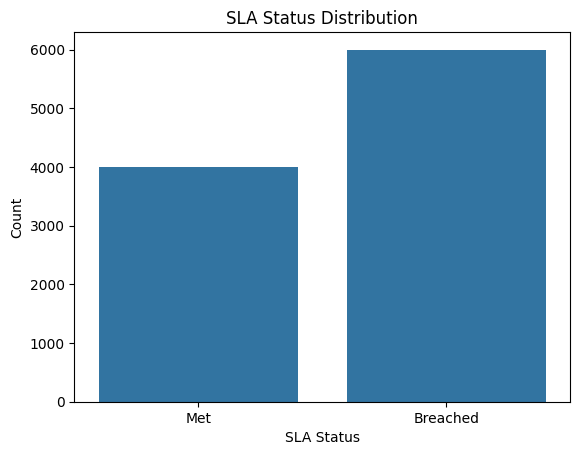

In [12]:
sns.countplot(x='SLA_Status', data=df)

plt.title("SLA Status Distribution")
plt.xlabel("SLA Status")
plt.ylabel("Count")
plt.show()

In [13]:
cor=df.corr(numeric_only=True)
cor

,Tasks_Assigned,Tasks_Completed,Avg_TAT_Hours,Error_Rate,Quality_Score,Escalations,Rework_Count,Experience_Years
Tasks_Assigned,1.000000,0.564714,0.027287,0.014075,-0.007935,0.035655,0.013252,-0.017781
Tasks_Completed,0.564714,1.000000,-0.006364,-0.030156,0.037886,0.008329,-0.040300,-0.009579
Avg_TAT_Hours,0.027287,-0.006364,1.000000,0.027266,-0.065401,0.030237,0.039194,0.016854
Error_Rate,0.014075,-0.030156,0.027266,1.000000,-0.041569,-0.022433,-0.039413,0.000934
Quality_Score,-0.007935,0.037886,-0.065401,-0.041569,1.000000,-0.020298,-0.043085,-0.008067
Escalations,0.035655,0.008329,0.030237,-0.022433,-0.020298,1.000000,-0.016772,0.011820
Rework_Count,0.013252,-0.040300,0.039194,-0.039413,-0.043085,-0.016772,1.000000,-0.030359
Experience_Years,-0.017781,-0.009579,0.016854,0.000934,-0.008067,0.011820,-0.030359,1.000000


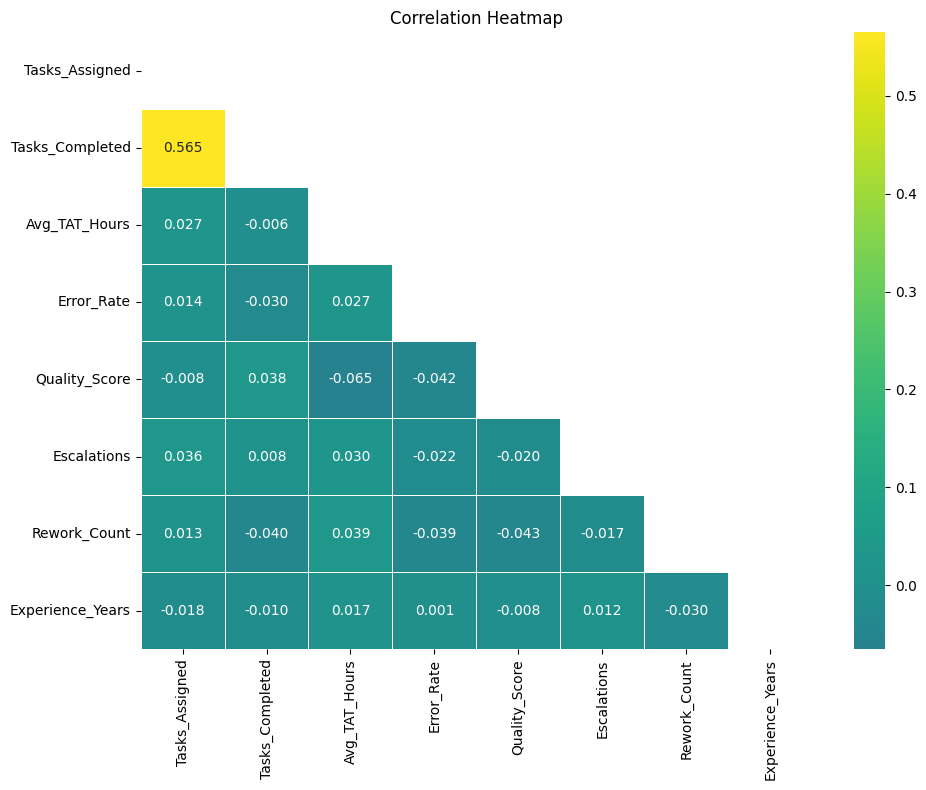

In [14]:
plt.figure(figsize=(10,8))
mask = np.triu(cor)
sns.heatmap(
    cor,
    mask=mask,
    annot=True,
    cmap='viridis',
    center=0,
    fmt='.3f',
    linewidths=0.5
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

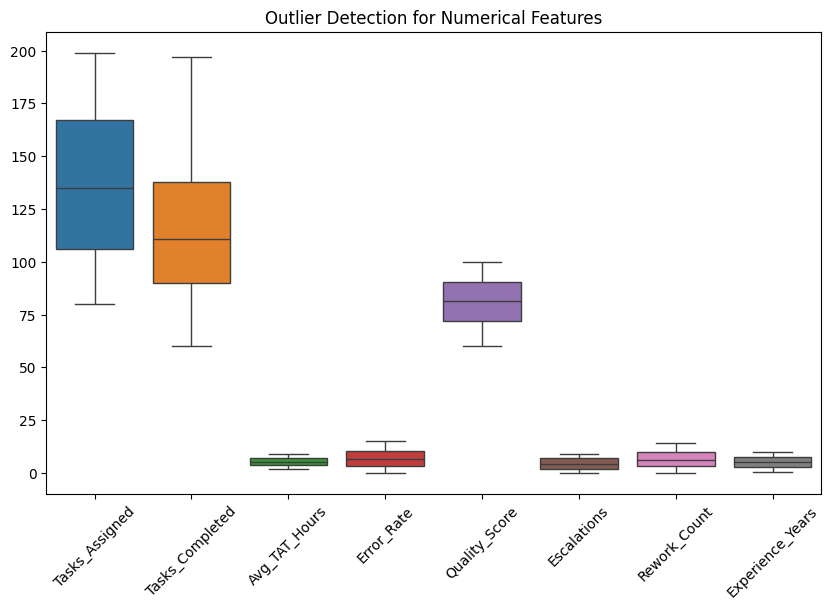

In [15]:
plt.figure(figsize=(10,6))
sns.boxplot(data=df.select_dtypes(include=['int64','float64']))
plt.xticks(rotation=45)
plt.title("Outlier Detection for Numerical Features")
plt.show()

In [16]:
df.isna().sum()

Employee_ID            0
Tasks_Assigned         0
Tasks_Completed        0
Avg_TAT_Hours       1099
Error_Rate          1099
Quality_Score       1099
Escalations            0
Rework_Count           0
Experience_Years       0
Team                   0
Shift                  0
SLA_Status             0
dtype: int64

In [17]:
df['SLA_Status'].unique()

array(['Met', 'Breached'], dtype=object)

In [18]:
df['SLA_Status'] = df['SLA_Status'].map({'Breached':0, 'Met':1})

In [19]:
df

,Employee_ID,Tasks_Assigned,Tasks_Completed,Avg_TAT_Hours,Error_Rate,Quality_Score,Escalations,Rework_Count,Experience_Years,Team,Shift,SLA_Status
0,EMP_6439,104,104,2.27,10.89,83.62,1,6,2.1,Support,Night,1
1,EMP_8984,108,108,2.54,3.88,79.96,6,13,1.4,Ads,Day,0
2,EMP_8559,184,85,4.24,11.60,98.72,3,11,7.9,Ads,Night,0
3,EMP_559,119,119,NaN,NaN,NaN,8,12,4.0,Support,Day,0
4,EMP_8376,139,139,5.13,8.30,88.55,6,14,7.4,Support,Day,0
...,...,...,...,...,...,...,...,...,...,...,...,...
9995,EMP_2467,120,120,3.50,8.78,64.52,9,0,0.9,QA,Night,0
9996,EMP_8837,192,105,5.03,8.91,76.35,8,7,2.8,Ads,Day,0
9997,EMP_2977,86,86,8.76,12.65,71.27,9,3,6.3,Moderation,Day,0
9998,EMP_6881,177,93,6.24,3.43,61.15,0,4,5.9,QA,Day,0


In [20]:
from sklearn.model_selection import train_test_split

df = pd.read_csv("employee_sla_status.csv")
df["Met"] = (df["SLA_Status"] == "Met").astype(int)        # 1 = Met, 0 = Breached
df["completion_ratio"] = df["Tasks_Completed"] / df["Tasks_Assigned"]
df["was_missing"] = df["Avg_TAT_Hours"].isna().astype(int)
df = pd.get_dummies(df.drop(columns=["Employee_ID", "SLA_Status"]), columns=["Team", "Shift"], drop_first=True, dtype=int)

X, y = df.drop(columns="Met"), df["Met"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

med = X_train.median()                 # medians from TRAIN only
X_train, X_test = X_train.fillna(med), X_test.fillna(med)

In [21]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from xgboost import XGBClassifier

models = {
    "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(9)),
    "RandomForest": RandomForestClassifier(200, random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(random_state=42, n_jobs=-1),
}
for name, m in models.items():
    print(name, round(cross_val_score(m, X_train, y_train, cv=5, scoring="f1_macro").mean(), 4))

LogReg 0.8234
KNN 0.8628
RandomForest 0.9813
XGBoost 0.9807


In [24]:
import optuna
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
optuna.logging.set_verbosity(optuna.logging.WARNING)

grid = GridSearchCV(XGBClassifier(random_state=42, n_jobs=-1),
    {"max_depth": [3, 5], "learning_rate": [0.05, 0.1], "n_estimators": [100, 200, 300]},
    scoring="f1_macro", cv=3).fit(X_train, y_train)

rand = RandomizedSearchCV(XGBClassifier(random_state=42, n_jobs=-1),
    {"max_depth": [3, 4, 5, 6, 7], "learning_rate": [0.03, 0.05, 0.1, 0.2], "n_estimators": [100, 200, 300, 400]},
    n_iter=12, scoring="f1_macro", cv=3, random_state=42).fit(X_train, y_train)

def objective(trial):
    m = XGBClassifier(max_depth=trial.suggest_int("max_depth", 3, 7),
                      learning_rate=trial.suggest_float("learning_rate", 0.03, 0.2),
                      n_estimators=trial.suggest_int("n_estimators", 100, 400),
                      random_state=42, n_jobs=-1)
    return cross_val_score(m, X_train, y_train, cv=3, scoring="f1_macro").mean()

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=12)
print("Grid", round(grid.best_score_, 4), "| Random", round(rand.best_score_, 4), "| Optuna", round(study.best_value, 4))

c:\Users\ALEENA THOMAS\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Grid 0.9764 | Random 0.9775 | Optuna 0.9797


              precision    recall  f1-score   support

    Breached       0.99      0.98      0.99      1200
         Met       0.98      0.99      0.98       800

    accuracy                           0.99      2000
   macro avg       0.99      0.99      0.99      2000
weighted avg       0.99      0.99      0.99      2000



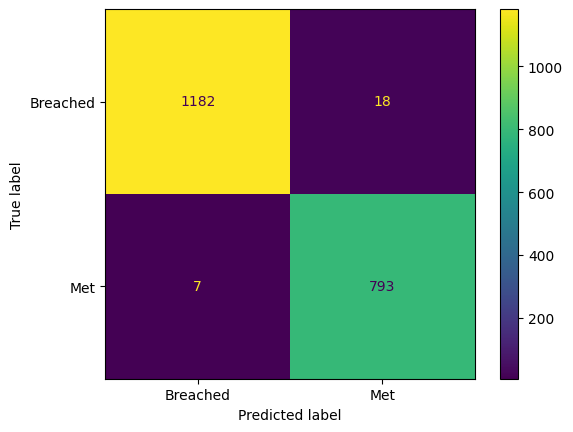

In [25]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

best = XGBClassifier(**study.best_params, random_state=42, n_jobs=-1).fit(X_train, y_train)   # use the best method's params
pred = best.predict(X_test)
print(classification_report(y_test, pred, target_names=["Breached", "Met"]))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Breached", "Met"])
plt.show()

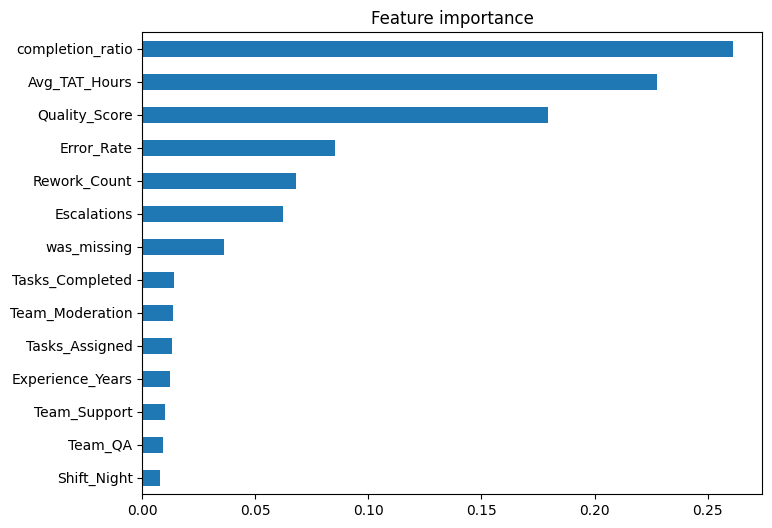

In [26]:
pd.Series(best.feature_importances_, X.columns).sort_values().plot(kind="barh", figsize=(8, 6), title="Feature importance")
plt.show()

In [27]:
from sklearn.metrics import f1_score

drop = ["completion_ratio", "Tasks_Completed", "Tasks_Assigned"]
m = XGBClassifier(**study.best_params, random_state=42, n_jobs=-1).fit(X_train.drop(columns=drop), y_train)
print("without task columns:", round(f1_score(y_test, m.predict(X_test.drop(columns=drop)), average="macro"), 4))

without task columns: 0.9292


In [28]:
risk = 1 - best.predict_proba(X_test)[:, 1]            # probability of breaching the SLA
flagged = risk >= 0.7
print("flagged:", flagged.sum(), "| actually breached among flagged:", round((y_test.values[flagged] == 0).mean(), 3))

flagged: 1169 | actually breached among flagged: 0.998


In [29]:
import json
best.save_model("sla_model.json")
json.dump({"columns": list(X.columns), "medians": med.to_dict()}, open("sla_meta.json", "w"))
